In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [91]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.stats as stats
import math

import acoustic_inversion as ai 

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [5]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.6

In [6]:
data1 = scipy.io.loadmat("../data/field_values20260707/field_values20260707.mat")


f = data1['f'].squeeze()
f_Vg = f[1:-1]
c = data1['soundspeed'].squeeze()
Vg = data1['Vg'].squeeze().transpose([1,0,2])
rho = data1['rho'].squeeze()
receiver_range = data1['range'][0,0]

In [7]:
arrival_times_data = receiver_range/Vg[c == TRUE_SOUNDSPEED, ...].squeeze()
arrival_times_replica = receiver_range/Vg

In [8]:
lk = ai.AcousticInversionLikelihood(arrival_times_data[:13])

In [9]:
likelihood_correct = lk.likelihood(arrival_times_replica[:,:13], 1e-2)
idx = np.arange(13)
idx_swapped = np.copy(idx)
idx_swapped[[0,1]] = np.array([1,0])

likelihood_swapped = lk.likelihood(arrival_times_replica[:,idx_swapped], 1e-2)

idx_shift = np.copy(idx)
idx_shift[12:] = idx_shift[12:] +1

likelihood_shift = lk.likelihood(arrival_times_replica[:,idx_shift], 1e-2)

#likelihood = likelihood/likelihood.sum()

In [10]:
idx_shift

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 13])

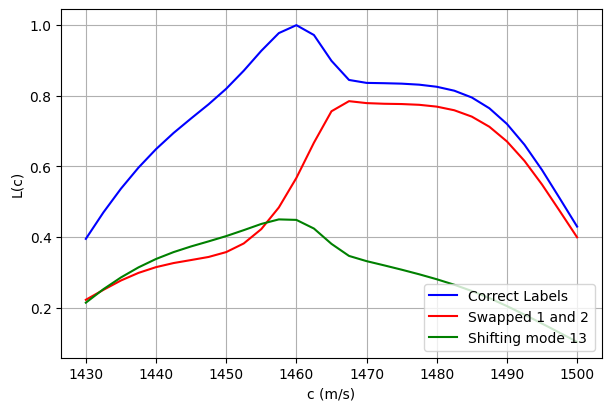

In [11]:
fig, ax = plt.subplots(layout = "constrained")

ax.plot(c, likelihood_correct, "b")
ax.plot(c, likelihood_swapped, "r")
ax.plot(c, likelihood_shift, "g")

ax.set_xlabel("c (m/s)")
ax.set_ylabel("L(c)")
ax.legend(["Correct Labels", "Swapped 1 and 2", "Shifting mode 13"], loc="lower right")


ax.grid()

fig.set_size_inches([6,4])

fig.savefig("../data/output/figures/lkhood_swapped12.png", dpi=300)

Note that this likelihood is not normalized by the sum.

In [81]:
ntrials = 1000
sigma = 2e-5

selected = [
    np.block([np.array([0,1]),
              np.arange(2,17)[np.random.binomial(1, .7, 15) ==1]])
    for n in range(ntrials)]

mode_labels_correct = selected
mode_labels = [s[[1,0,*range(2,len(s))]] for s in selected]

In [82]:
normalize01 = lambda x: x/x.sum()
var = lambda p,x: p @ (x**2) - (p @ x)**2

In [83]:
likelihood_mc_correct = np.empty((ntrials, len(c)))
likelihood_mc = np.empty((ntrials, len(c)))
var_mc_correct = np.empty(ntrials)
var_mc = np.empty(ntrials)
for trial in range(ntrials):
    noisy_atimes_data = arrival_times_data[selected[trial]]
    noisy_atimes_data = noisy_atimes_data + np.random.normal(size=noisy_atimes_data.shape)*sigma
    coefs = np.array([ai.constrained_polyfit(f_Vg, tau, 2, 5e-7) for tau in noisy_atimes_data])

    atimes_data = np.array([np.polyval(co, f_Vg) for co in coefs])
    
    atimes_replica_correct = arrival_times_replica[:, mode_labels_correct[trial]]
    atimes_replica = arrival_times_replica[:, mode_labels[trial]]
    
    
    lk_mc = ai.AcousticInversionLikelihood(atimes_data)
    likelihood_mc_correct[trial] = lk_mc.likelihood(atimes_replica_correct, 1e-2)
    likelihood_mc[trial] = lk_mc.likelihood(atimes_replica, 1e-2)
    
    var_mc_correct[trial] = var(likelihood_mc_correct[trial], c)
    var_mc[trial] = var(likelihood_mc[trial], c)
    

In [84]:
likelihood_mc.shape

(1000, 29)

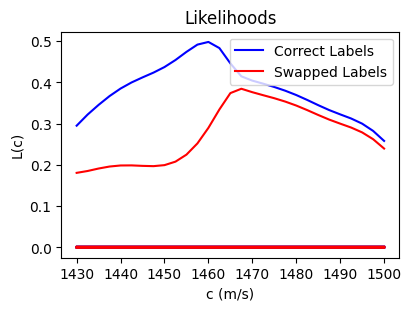

In [85]:
fig, ax = plt.subplots(layout="constrained")

l0 = ax.plot(c, likelihood_mc_correct[::50].T, 'b', label="$\\delta=0$")
l1 = ax.plot(c, likelihood_mc[::50].T, 'r', label="$\\delta=0$")

ax.set_title("Likelihoods")
ax.set_xlabel("c (m/s)")
ax.set_ylabel("L(c)")

ax.legend([l0[0], l1[0]], ["Correct Labels", "Swapped Labels"])

fig.set_size_inches([4,3])

fig.savefig("../data/output/figures/perturbed_likelihoods_swap12.png", dpi=600)

In [86]:
np.sum(likelihood_mc_correct > likelihood_mc)

np.int64(29000)

In [87]:
nmodes = np.array([len(s) for s in selected])

In [88]:
np.unique(nmodes)

array([ 7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

<BarContainer object of 11 artists>

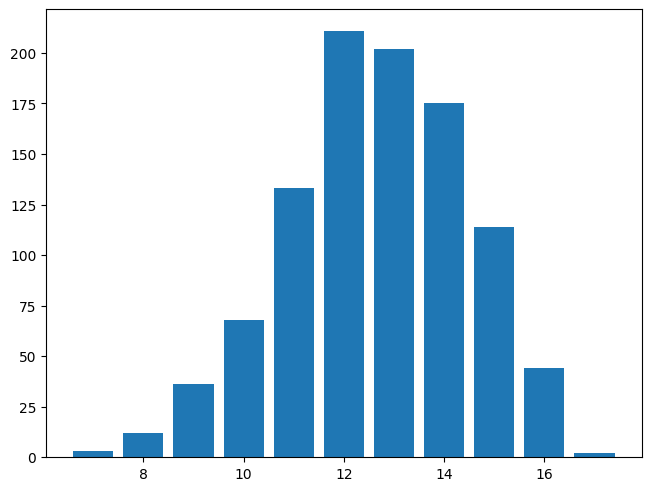

In [89]:
nmodes_dist = np.array([np.sum(nmodes == n) for n in np.unique(nmodes)])

fig, ax = plt.subplots(layout = "constrained")

ax.bar(np.unique(nmodes), nmodes_dist)

In [72]:
nmodes_vs_lk_correct = np.array([np.quantile(np.max(likelihood_mc_correct[nmodes == n], axis=1), [.1, .5, .9]) for n in np.unique(nmodes)])
nmodes_vs_lk = np.array([np.quantile(np.max(likelihood_mc[nmodes == n], axis = 1), [.1, .5, .9]) for n in np.unique(nmodes)])

<ErrorbarContainer object of 3 artists>

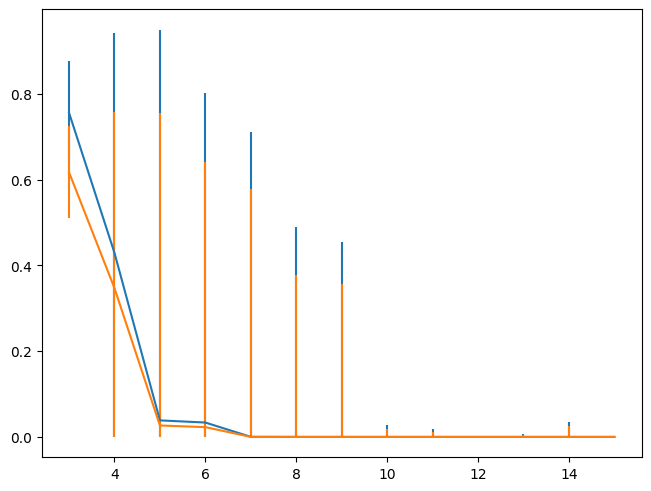

In [73]:
fig, ax = plt.subplots(layout = "constrained")

center = nmodes_vs_lk_correct[:,1]
yerr = np.abs(nmodes_vs_lk_correct[:,[0,2]].T - nmodes_vs_lk_correct[:,1])

ax.errorbar(np.unique(nmodes), center, yerr=yerr)

center = nmodes_vs_lk[:,1]
yerr = np.abs(nmodes_vs_lk[:,[0,2]].T - nmodes_vs_lk[:,1])


ax.errorbar(np.unique(nmodes), center, yerr=yerr)

In [75]:
modes_vs_lk_correct = np.array([np.quantile(np.max(likelihood_mc_correct[[np.isin(n, v) for v in selected ]],axis=0), [.1, .5, .9])   for n in range(3,16)])
modes_vs_lk = np.array([np.quantile(np.max(likelihood_mc[[np.isin(n, v) for v in selected ]],axis=0), [.1, .5, .9])   for n in range(3,16)])

<ErrorbarContainer object of 3 artists>

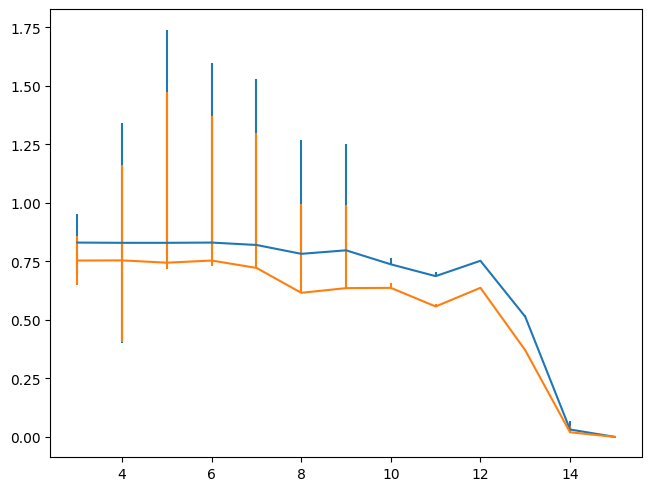

In [76]:
fig, ax = plt.subplots(layout = "constrained")

center = modes_vs_lk_correct[:,1]
yerr = np.abs(nmodes_vs_lk_correct[:,[0,2]].T - nmodes_vs_lk_correct[:,1])

ax.errorbar(range(3,16), center, yerr=yerr)

center = modes_vs_lk[:,1]
yerr = np.abs(nmodes_vs_lk[:,[0,2]].T - nmodes_vs_lk[:,1])

ax.errorbar(range(3,16), center, yerr=yerr)

In [44]:
nmodes_vs_lk_correct[:, [0,2]]

array([[4.36797465e-01, 8.01693998e-01],
       [7.40631156e-05, 8.36174316e-01],
       [7.64977236e-07, 8.12357822e-01],
       [2.09874426e-08, 6.86672791e-01],
       [8.96379149e-11, 5.42584511e-01],
       [5.04892203e-11, 4.10976521e-01],
       [2.41717566e-11, 3.65325964e-01],
       [2.01847218e-12, 2.49911421e-02],
       [9.67853255e-13, 1.30191037e-02],
       [5.28226186e-13, 4.71528263e-06],
       [3.79095495e-13, 2.76903559e-03],
       [1.36410934e-13, 9.79859769e-03],
       [9.15480623e-14, 8.53747786e-13]])

In [93]:
math.comb(4, 2)

6